<div style="font-family: 'Vazirmatn', Tahoma, sans-serif; direction: rtl; background: linear-gradient(135deg, #052E2B 0%, #134E4A 60%, #115E59 100%); border-radius: 16px; padding: 30px 40px; margin: -16px -16px 20px -16px; position: relative; overflow: hidden; text-align: center;">
  <div style="font-size: 28pt; font-weight: 700; color: #CCFBF1; margin: 0 0 12px;">داده‌کاوی</div>
  <div style="font-size: 16pt; font-weight: 500; color: #99F6E4; margin: 0 0 12px;">دانشگاه آزاد شیراز — دانشکده مهندسی کامپیوتر</div>
  <span style="display: inline-block; background: #FEF3C7; color: #134E4A; font-size: 14pt; font-weight: 600; padding: 6px 18px; border-radius: 20px; margin-bottom: 20px;">ترم اول سال تحصیلی ۱۴۰۶-۱۴۰۵</span>
  <hr style="border: none; height: 1px; background: rgba(255,255,255,0.15); margin: 20px 0;"/>
  <div style="font-size: 18pt; font-weight: 700; color: #FEF3C7; margin: 0 0 16px;">    فصل سوم: Data warehousing and online analytical processing</div>
  <div style="background: rgba(255,255,255,0.08); border-radius: 10px; padding: 16px 20px; font-size: 15pt; color: #CCFBF1; line-height: 2.2;">
    <b style="color: #CCFBF1; font-weight: 600;">استاد:</b> <span style="color: #F8FAFC;">دکتر امین اسکندری</span><br>
    <b style="color: #CCFBF1; font-weight: 600;">تیم طراحی:</b> <span style="color: #F1F5F9;">حمید نامجو، امیرحسین همتی، امیرمحمد اسدجو، علی نیکوان، رضا لیاقت، علیرضا مقدس، گلنوش حسین‌پور، الهام ایزدی</span>
  </div>
</div>

<div id="c3-s5-3" style="font-family: 'Vazirmatn', Tahoma, sans-serif; direction: ltr; color: #3D5A47; border-radius: 10px; padding: 10px 10px; font-size: 18pt; font-weight: 700; margin: 0px 0 10px; display: flex; align-items: center; gap: 10px;">
  <span style="font-size: 20pt;"></span> 3.5.3 Precomputing shell fragments for fast high-dimensional OLAP
</div>

<div style="font-family: 'Vazirmatn', Tahoma, sans-serif; direction: rtl; border-radius: 0 10px 10px 0; padding: 16px 20px; margin: 14px 0; border-right: 5px solid #B45309; font-size: 15pt; line-height: 2.2; background: #FFFBEB; color: #78350F; box-sizing: border-box;">

  <div style="font-size: 16pt; text-align: center; font-weight: 700; margin-bottom: 8px; color: #B45309;">
    مثال عملی: پاسخ‌دهی آنی به کوئری‌های چندبعدی آمازون با پیش‌محاسبه تکه‌های پوسته (Shell Fragments) 🛠️
  </div>

  <p style="font-size: 15pt; text-align: right; margin: 0 0 10px;">
    وقتی یک مکعب داده در انبار داده آمازون دارای تعداد ابعاد بسیار زیادی باشد (مثلاً ۳۰ بعد مختلف مانند سن خریدار، جنسیت، شهر، برند، رنگ، تخفیف، روش پرداخت و غیره)، فرمول $2^{30}$ بیش از ۱ میلیارد مکعب‌واره مختلف تولید می‌کند! پیش‌محاسبه کامل همه این تجمیع‌ها (Full Materialization) به حافظه‌ای پتابایتی نیاز دارد و کاملاً غیرممکن است. برای حل این مشکل در OLAP با ابعاد بالا (High-Dimensional OLAP)، از راهبرد پیش‌محاسبه تکه‌های پوسته (Shell Fragments) استفاده می‌شود.
  </p>

  <p style="font-size: 15pt; text-align: right; margin: 0 0 10px;">
    مفاهیم کلیدی راهبرد تکه‌های پوسته:
  </p>

  <p style="font-size: 15pt; text-align: right; margin: 0 0 10px;">
    ۱. تقسیم ابعاد زیاد به گروه‌های کوچک‌تر (Shell Fragments):<br>
    به جای ترکیب تمام ۳۰ بعد با یکدیگر، ابعاد به تکه‌های پوسته کوچک‌تر و کم‌بعد (مثلاً گروه‌های ۲ یا ۳ بعدی مرتبط با هم) تقسیم می‌شوند:<br>
    &nbsp;&nbsp;&nbsp;• تکه پوسته اول ($A, B, C$): مربوط به مشخصات مشتری (سن، جنسیت، شهر).<br>
    &nbsp;&nbsp;&nbsp;• تکه پوسته دوم ($D, E, F$): مربوط به مشخصات محصول (برند، دسته‌بندی، رنگ).<br>
    &nbsp;&nbsp;&nbsp;• تکه پوسته سوم ($G, H$): مربوط به زمان و روش پرداخت.
  </p>

  <p style="font-size: 15pt; text-align: right; margin: 0 0 10px;">
    ۲. پیش‌محاسبه جداگانه تکه‌ها (Precomputing Fragments):<br>
    تجمیع‌ها فقط داخل هر تکه پوسته به‌صورت جداگانه محاسبه و ذخیره می‌شوند. تعداد مکعب‌واره‌های کل از حالت انفجاری $2^{30}$ به مجموع ضرب‌های کوچک‌تر (مثلاً $2^3 + 2^3 + 2^2 = 24$ مکعب‌واره) کاهش می‌یابد!
  </p>

  <p style="font-size: 15pt; text-align: right; margin: 0 0 10px;">
    ۳. ترکیب پویا هنگام اجرای کوئری (On-the-Fly Fragment Combination):<br>
    وقتی کوئری معینی وارد می‌شود که ابعاد مختلف را هم‌زمان می‌خواهد، سیستم به جای اسکن کل جدول خام، تکه‌های پوسته‌ای پیش‌محاسبه‌شده مرتبط را با شناسه سطرها (Inverted Index / RID List) با یکدیگر ترکیب و تقاطع می‌دهد تا جواب در کسری از ثانیه آماده شود.
  </p>

  <p style="font-size: 15pt; text-align: right; margin: 0;">
    نتیجه: این راهبرد مانع از انفجار حافظه در OLAPهای با ابعاد بالا شده و سرعت پاسخ به کوئری‌ها را فوق‌العاده بالا می‌برد.<br><br>
    <div style="text-align:center; font-weight:bold;">
      خروجی: حل مشکل نفرین ابعاد در انبار داده با شکستن کل ابعاد به تکه‌های پوسته مستقل و فشرده
    </div>
  </p>

</div>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display, HTML

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", rc={
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11
})
plt.rcParams['figure.dpi'] = 135
np.random.seed(42)

def display_academic_text(text, type="normal"):
    """Renders text in a strict academic format."""
    styles = {
        "main_title": (
            "font-family: Tahoma, sans-serif; color: #2c3e50; font-size: 24px; "
            "font-weight: bold; text-align: center; border-bottom: 2px solid #34495e; "
            "padding-bottom: 15px; margin: 30px 0;"
        ),
        "sub_title": (
            "font-family: Tahoma, sans-serif; color: #34495e; font-size: 19px; "
            "font-weight: bold; border-right: 5px solid #2980b9; padding-right: 15px; "
            "margin: 40px 0px 20px 0px; background-color: #ecf0f1; padding: 12px; "
            "border-radius: 4px;"
        ),
        "paragraph": (
            "font-family: Tahoma, sans-serif; color: #2c3e50; font-size: 16px; "
            "margin-bottom: 20px; line-height: 1.8; text-align: justify;"
        ),
        "insight": (
            "font-family: Tahoma, sans-serif; color: #16a085; font-size: 16px; "
            "font-weight: bold; background-color: #e8f8f5; padding: 20px; "
            "border-left: 5px solid #1abc9c; margin: 30px 0; line-height: 1.8; "
            "text-align: justify;"
        )
    }
    display(HTML(f"<div dir='rtl' style='text-align: right; {styles[type]}'>{text}</div>"))

def get_protected_css():
    return """
    <style>
    .academic-table-wrapper { 
        direction: ltr !important; overflow-x: auto !important; width: 100% !important; 
        background-color: #fff; border: 1px solid #bdc3c7; border-radius: 4px; 
        box-shadow: 0 3px 6px rgba(0,0,0,0.08); 
    }
    table.strict-tbl { 
        border-collapse: collapse !important; width: 100% !important; margin: 0 !important; 
        font-family: inherit !important; font-size: 14px !important; 
        table-layout: auto !important; border: none !important; 
    }
    table.strict-tbl thead th { 
        background-color: #2c3e50 !important; color: #ffffff !important; 
        padding: 12px 18px !important; text-align: center !important; 
        border: 1px solid #34495e !important; white-space: nowrap !important; font-weight: bold !important; 
    }
    table.strict-tbl tbody td { 
        padding: 10px 18px !important; text-align: center !important; 
        border: 1px solid #bdc3c7 !important; white-space: nowrap !important; color: #2c3e50 !important; 
    }
    table.strict-tbl tbody tr:nth-child(even) td { background-color: #f8f9fa !important; }
    table.strict-tbl tbody tr:hover td { background-color: #e8ecef !important; }
    </style>
    """

def display_side_by_side_datasets(dfs, titles):
    col_html_list = []
    for i, (df, title) in enumerate(zip(dfs, titles)):
        table_html = df.to_html(index=False, classes=['strict-tbl'], border=0, float_format=lambda x: f"{x:.2f}")
        col_html = f"""
        <div class="flex-column" style="flex: 1 1 0; min-width: 0; display: flex; flex-direction: column;">
            <div style="background-color: #2c3e50; color: white; padding: 12px; text-align: center; font-family: Tahoma, sans-serif; font-weight: bold; font-size: 15px; border-radius: 4px 4px 0 0;">
                {title}
            </div>
            <div class="academic-table-wrapper" style="margin-top: 0; border-top: none;">
                {table_html}
            </div>
        </div>
        """
        col_html_list.append(col_html)
    
    html = f"<div style='display: flex; flex-direction: row; justify-content: space-between; gap: 20px; width: 100%; max-width: 100%; margin: 20px 0 35px 0; box-sizing: border-box;'>{''.join(col_html_list)}</div>"
    display(HTML(get_protected_css() + html))

RID,AgeGroup,Gender,City,Brand,Category,Color,Payment,ShipType,Season,Sales_USD
0,Senior,M,LA,Sony,Tech,White,Cash,Express,Winter,204.41
1,Young,F,Chicago,Samsung,Home,Black,Card,Express,Summer,225.54
2,Senior,M,LA,Sony,Home,Blue,Card,Express,Winter,428.34
3,Senior,F,Chicago,Samsung,Home,Black,Card,Express,Summer,65.32
4,Young,F,LA,Apple,Tech,Blue,Card,Standard,Winter,460.91


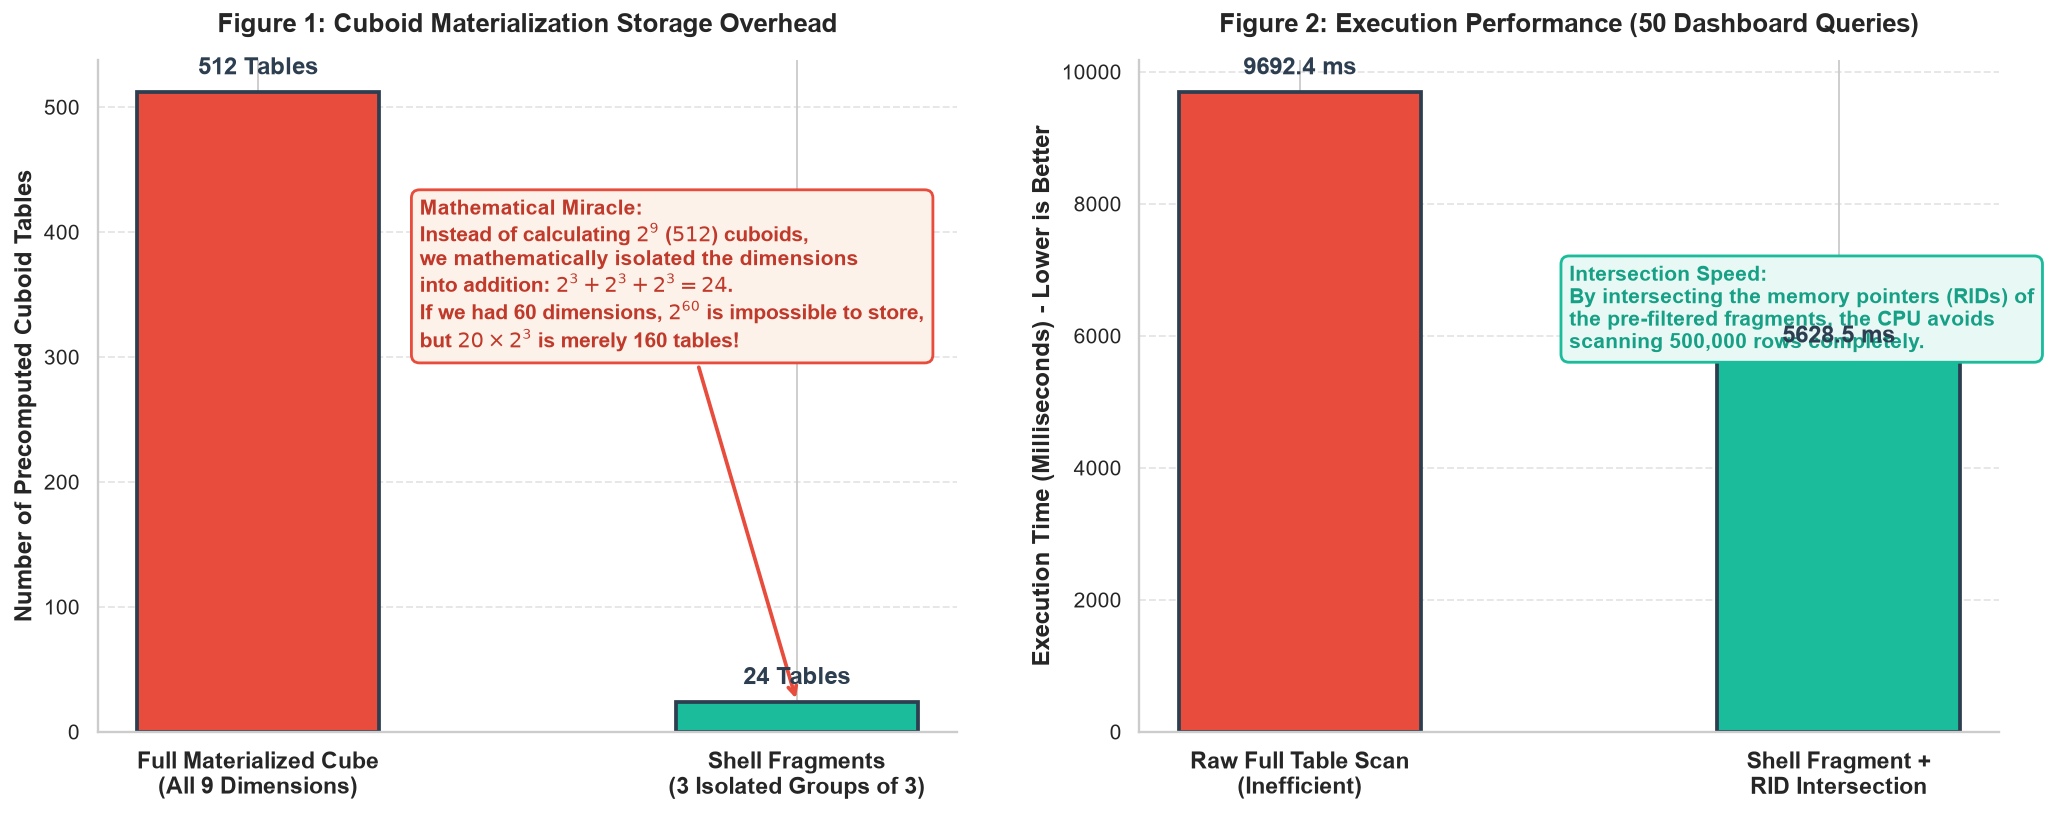

In [4]:
display_academic_text(
    "پاسخ‌دهی آنی به کوئری‌های چندبُعدی آمازون با پیش‌محاسبه تکه‌های پوسته (Shell Fragments) 🛠️", 
    "main_title"
)

display_academic_text(
    "وقتی یک مکعب داده در انبار داده آمازون دارای تعداد ابعاد (Dimensions) بسیار زیادی باشد (مثلاً ۳۰ بُعد مختلف مانند سن، جنسیت، شهر، برند، رنگ، تخفیف، روش پرداخت و...)، "
    "فرمول ریاضی نشان‌دهنده پدیده‌ای مرگبار به نام <b>«نفرین ابعاد» (Curse of Dimensionality)</b> در صورت تمایل به متریالیزه کردن کامل است:", 
    "paragraph"
)

display_academic_text(
    r"$$\text{Full Materialization Cuboids} = 2^{30} > 1,000,000,000 \text{ Cuboids}$$", 
    "paragraph"
)

display_academic_text(
    "پیش‌محاسبهٔ کاملِ همهٔ این تجمیع‌ها به حافظه‌ای در مقیاس اگزابایت نیاز دارد و عملاً غیرممکن است. برای حل این مشکل، از راهبرد پیش‌محاسبهٔ <b>تکه‌های پوسته (Shell Fragments)</b> استفاده می‌شود:", 
    "sub_title"
)

display_academic_text(
    "۱. <b>تقسیم ابعاد (Dimension Partitioning):</b> ابعاد سیستم به گروه‌های کوچک‌تر (مثلاً ۳ بُعدی) مثل <i>مشتری (A,B,C)</i>، <i>محصول (D,E,F)</i> و <i>سفارش (G,H,I)</i> تقسیم می‌شوند.<br>"
    "۲. <b>پیش‌محاسبه جداگانه (Independent Aggregation):</b> تعداد مکعب‌واره‌های کل از حالت نمایی و ضربی ($2^9$)، به حالت جمعی تغییر می‌یابد ($2^3 + 2^3 + 2^3$).<br>"
    "۳. <b>ترکیب پویا (Inverted Index / RID Lists):</b> سیستم با استفاده از شناسهٔ سطرها (RID)، در زمان کوئری‌گیری، تکه‌های موردنیاز را با عملگر تقاطع (Set Intersection / Bitwise AND) استخراج می‌کند.", 
    "paragraph"
)

# ==========================================================
# 3. DATA GENERATION & CONCEPTUAL DEFINITION
# ==========================================================
n_rows = 500_000

df = pd.DataFrame({
    'RID': np.arange(n_rows),
    # Customer Dimensions (Fragment 1)
    'AgeGroup': np.random.choice(['Young', 'Adult', 'Senior'], n_rows),
    'Gender': np.random.choice(['M', 'F'], n_rows),
    'City': np.random.choice(['NYC', 'LA', 'Chicago'], n_rows),
    # Product Dimensions (Fragment 2)
    'Brand': np.random.choice(['Apple', 'Samsung', 'Sony'], n_rows),
    'Category': np.random.choice(['Tech', 'Home'], n_rows),
    'Color': np.random.choice(['Black', 'White', 'Blue'], n_rows),
    # Order Dimensions (Fragment 3)
    'Payment': np.random.choice(['Card', 'Cash'], n_rows),
    'ShipType': np.random.choice(['Express', 'Standard'], n_rows),
    'Season': np.random.choice(['Winter', 'Summer'], n_rows),
    # Measure
    'Sales_USD': np.random.uniform(20.0, 500.0, n_rows)
})

# Curse of Dimensionality Mathematics (9 Dimensions total)
n_dimensions = 9
full_cube_cuboids = 2 ** n_dimensions

# Define Shell Fragments
shells = {
    'Customer_Shell': ['AgeGroup', 'Gender', 'City'],
    'Product_Shell': ['Brand', 'Category', 'Color'],
    'Order_Shell': ['Payment', 'ShipType', 'Season']
}

display_side_by_side_datasets(
    [df.head(5).reset_index(drop=True)],
    [f"مجموعه داده خام آمازون: دارای {n_rows:,} رکورد تراکنشی و {n_dimensions} بُعد تحلیلی"]
)

# ==========================================================
# 4. BUILDING RID LISTS (INVERTED INDEXES)
# ==========================================================
display_academic_text("مرحله نخست: ساخت ایندکس‌های معکوس (Inverted Indexes) در پس‌زمینه (ETL)", "sub_title")

def build_fragment(df, dimensions):
    fragment = {}
    for key, group in df.groupby(dimensions, sort=False):
        if not isinstance(key, tuple):
            key = (key,)
        fragment[key] = set(group['RID'])
    return fragment

start = time.perf_counter()
fragment_indexes = {}

for name, dimensions in shells.items():
    fragment_indexes[name] = build_fragment(df, dimensions)

precompute_time = (time.perf_counter() - start) * 1000

display_academic_text(
    f"<b>زمان پیش‌محاسبه پوسته‌ها و استخراج پوسترهای RID:</b> <b>{precompute_time:.1f} میلی‌ثانیه</b> "
    f"(این عملیات تنها یک بار در پس‌زمینه سرور انجام می‌شود).", 
    "insight"
)

# ==========================================================
# 5. SHELL FRAGMENT QUERY EXECUTION
# ==========================================================
display_academic_text("مرحله دوم: شبیه‌سازی کوئری در زمان اجرا (Run-time Execution)", "sub_title")

def query_fragment(fragment_name, conditions):
    dimensions = shells[fragment_name]
    index = fragment_indexes[fragment_name]
    matching_rids = set()

    for key, rids in index.items():
        match = True
        for dimension, value in conditions.items():
            position = dimensions.index(dimension)
            if key[position] != value:
                match = False
                break
        if match:
            matching_rids.update(rids)
            
    return matching_rids

n_queries = 50

# Method A: Full Table Scan
start = time.perf_counter()
for _ in range(n_queries):
    raw_result = df[
        (df['AgeGroup'] == 'Adult') &
        (df['Brand'] == 'Apple') &
        (df['Payment'] == 'Card')
    ]['Sales_USD'].sum()
raw_time = (time.perf_counter() - start) * 1000

# Method B: Shell Fragment + RID Intersection
start = time.perf_counter()
for _ in range(n_queries):
    rids_age = query_fragment('Customer_Shell', {'AgeGroup': 'Adult'})
    rids_brand = query_fragment('Product_Shell', {'Brand': 'Apple'})
    rids_payment = query_fragment('Order_Shell', {'Payment': 'Card'})

    # Intersection of RID Lists
    final_rids = rids_age & rids_brand & rids_payment

    shell_result = df.loc[df['RID'].isin(final_rids), 'Sales_USD'].sum()
shell_time = (time.perf_counter() - start) * 1000

is_verified = np.isclose(raw_result, shell_result)

display_academic_text(
    f"<b>تأیید یکپارچگی محاسبات:</b> <b>{is_verified}</b> "
    f"(نتیجهِ کُلِ فروش محاسبه شده از هر دو روش کاملاً یکسان و برابر با <b>${raw_result:,.2f}</b> است.)", 
    "paragraph"
)

# ==========================================================
# 6. VISUAL ANALYTICS (ACADEMIC BLUE)
# ==========================================================
shell_customer_cuboids = 2 ** len(shells['Customer_Shell'])
shell_product_cuboids = 2 ** len(shells['Product_Shell'])
shell_order_cuboids = 2 ** len(shells['Order_Shell'])

shell_total_cuboids = shell_customer_cuboids + shell_product_cuboids + shell_order_cuboids

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), dpi=135)

# Subplot 1: Cuboid Explosion
labels = ['Full Materialized Cube\n(All 9 Dimensions)', 'Shell Fragments\n(3 Isolated Groups of 3)']
# FIX: Ensure full_cube_cuboids is used correctly here
values = [full_cube_cuboids, shell_total_cuboids]

bars = axes[0].bar(
    labels, values, color=['#e74c3c', '#1abc9c'], edgecolor='#2c3e50', linewidth=2.0, width=0.45
)

axes[0].annotate(
    "Mathematical Miracle:\nInstead of calculating $2^9$ ($512$) cuboids,\nwe mathematically isolated the dimensions\ninto addition: $2^3 + 2^3 + 2^3 = 24$.\nIf we had 60 dimensions, $2^{60}$ is impossible to store,\nbut $20 \\times 2^3$ is merely 160 tables!",
    # FIX: Ensure full_cube_cuboids is used correctly here as well
    xy=(1.0, shell_total_cuboids), xytext=(0.3, full_cube_cuboids * 0.6),
    fontsize=11, fontweight='bold', color='#c0392b',
    arrowprops=dict(arrowstyle="->", color="#e74c3c", lw=2.0),
    bbox=dict(boxstyle="round,pad=0.4", fc="#fdf2e9", ec="#e74c3c", lw=1.5)
)

axes[0].set_title('Figure 1: Cuboid Materialization Storage Overhead', fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('Number of Precomputed Cuboid Tables', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].set_xticklabels(labels, fontweight='bold', fontsize=12)

for bar, value in zip(bars, values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, value + (max(values) * 0.02),
        f'{value:,} Tables', ha='center', va='bottom', fontweight='bold', fontsize=13, color='#2c3e50'
    )

# Subplot 2: Query Performance
labels_time = ['Raw Full Table Scan\n(Inefficient)', 'Shell Fragment +\nRID Intersection']
values_time = [raw_time, shell_time]

bars2 = axes[1].bar(
    labels_time, values_time, color=['#e74c3c', '#1abc9c'], edgecolor='#2c3e50', linewidth=2.0, width=0.45
)

axes[1].annotate(
    "Intersection Speed:\nBy intersecting the memory pointers (RIDs) of\nthe pre-filtered fragments, the CPU avoids\nscanning 500,000 rows completely.",
    xy=(1.0, shell_time), xytext=(0.5, raw_time * 0.6),
    fontsize=11, fontweight='bold', color='#16a085',
    arrowprops=dict(arrowstyle="->", color="#1abc9c", lw=2.0),
    bbox=dict(boxstyle="round,pad=0.4", fc="#e8f8f5", ec="#1abc9c", lw=1.5)
)

axes[1].set_title(f'Figure 2: Execution Performance ({n_queries} Dashboard Queries)', fontsize=14, fontweight='bold', pad=15)
axes[1].set_ylabel('Execution Time (Milliseconds) - Lower is Better', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].set_xticklabels(labels_time, fontweight='bold', fontsize=12)

for bar, value in zip(bars2, values_time):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value + (max(values_time) * 0.02),
        f'{value:.1f} ms', ha='center', va='bottom', fontweight='bold', fontsize=13, color='#2c3e50'
    )

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(pad=2.0)
plt.show()

# ==========================================================
# 7. STRATEGIC CONCLUSION
# ==========================================================
insight_conclusion = (
    r"<b>نتیجه استراتژیک در سیستم‌های OLAP (Strategic Implication):</b><br>"
    r"راهبرد <b>تکه‌های پوسته (Shell Fragments)</b> یک معجزهٔ ریاضیات و علوم کامپیوتر در سیستم‌های تحلیلی است.<br>"
    r"با تقسیم ۹ بُعدِ سیستم به ۳ دستهٔ ۳ بُعدیِ کاملاً مستقل (ایزوله‌سازی فیزیکی)، ما تعدادِ تجمیع‌هایِ پیش‌محاسبه‌شونده را از حالت <i>نمایی و ضربی</i> ($2^9 = 512$) "
    r"به حالت <i>خطی و جمعی</i> ($2^3 + 2^3 + 2^3 = 24$) کاهش دادیم. این یعنی صرفه‌جوییِ عظیمی در فضای دیسک رخ داده است (همانطور که در گراف ۱ مشهود است).<br><br>"
    r"در زمانِ کوئری‌گیری در داشبوردها، پایگاه داده صرفاً <b>شناسهٔ سطرها (RIDs / Inverted Index)</b> را متقاطع می‌کند (عملگر تقاطعِ مجموعه‌ها) که در موتورهای واقعیِ مبتنی بر زبان‌های C/C++، "
    r"این عملیاتِ حافظه‌ای هزاران بار سریع‌تر از پیمایش و اسکنِ کُلِ جدول است."
)
display_academic_text(insight_conclusion, "insight")

<div dir="rtl" style="font-family:Vazirmatn, Tahoma, sans-serif; line-height:300%; background:#fafafa; border:1px solid #ccc; border-radius:12px; padding:25px; text-align:right;">

<p style="font-size:18pt; text-align:center;">
        <span style="font-size:24pt; font-weight:bold; color:#1B263B;">
            توضیح مثال کد پایتون
        </span>
        💻
    </p>

<p style="font-size:16pt; text-align:right;">
        در این مثال، مفهوم <b>تکه‌های پوسته (Shell Fragments)</b>
        برای پاسخ‌گویی به کوئری‌های چندبعدی در یک محیط OLAP با ابعاد بالا شبیه‌سازی شده است.
    </p>

<ul style="font-size:16pt; text-align:right;">

<li>
            <b>ایجاد داده چندبعدی:</b>
            یک مجموعه داده شامل <b>۱۰۰,۰۰۰ تراکنش</b> و
            <b>۸ بُعد</b> مختلف ایجاد شده است.
            این ابعاد در سه گروه اصلی قرار گرفته‌اند:
            
<ul>
                <li>
                    <b>تکه پوسته مشتری:</b>
                    گروه سنی، جنسیت و شهر.
                </li>

<li>
                    <b>تکه پوسته محصول:</b>
                    برند، دسته‌بندی و رنگ.
                </li>

<li>
                    <b>تکه پوسته سفارش:</b>
                    روش پرداخت، نوع ارسال و فصل.
                </li>
            </ul>
        </li>

<li>
            <b>نفرین ابعاد:</b>
            در یک مکعب داده با <b>N بُعد</b>،
            تعداد Cuboidهای ممکن در حالت Full Materialization
            برابر با <b>2<sup>N</sup></b> است.
            بنابراین برای ۳۰ بُعد، تعداد Cuboidهای ممکن برابر با
            <b>1,073,741,824</b> خواهد بود.
            این رشد نمایی، محاسبه و ذخیره‌سازی تمام Cuboidها را بسیار پرهزینه می‌کند.
        </li>

<li>
            <b>پیاده‌سازی Shell Fragments:</b>
            به جای پیش‌محاسبه تمام ترکیب‌های ممکن از همه ابعاد،
            ابعاد مرتبط در سه گروه کوچک‌تر تقسیم شده و برای هر گروه
            یک ساختار <b>RID Index</b> ایجاد می‌شود.
            این ساختار، شناسه رکوردهای مربوط به هر ترکیب از مقادیر ابعاد
            را نگهداری می‌کند.
        </li>

<li>
            <b>پاسخ‌گویی به کوئری چندبعدی:</b>
            برای کوئری نمونه:

<div style="text-align:center; margin:15px 0; padding:12px; background:#eef2f7; border-radius:8px;">
                <b>
                    AgeGroup = Adult &nbsp; | &nbsp;
                    Brand = Apple &nbsp; | &nbsp;
                    Payment = Card
                </b>
            </div>

 سیستم ابتدا RIDهای منطبق با هر شرط را از تکه پوسته مربوطه
            استخراج می‌کند و سپس با استفاده از عملگر
            <b>Intersection (∩)</b>،
            رکوردهایی را پیدا می‌کند که هر سه شرط را به‌طور هم‌زمان داشته باشند.
</li>

 <li>
            <b>محاسبه دقیق نتیجه:</b>
            پس از به‌دست‌آوردن RIDهای نهایی، مقدار
            <b>Sales_USD</b>
            برای همان رکوردها محاسبه می‌شود.
            بنابراین نتیجه روش Shell Fragment باید با نتیجه
            اسکن مستقیم جدول خام یکسان باشد.
        </li>

<li>
            <b>صرفه‌جویی در محاسبات:</b>
            هدف Shell Fragments این است که به جای ساخت و نگهداری
            کل فضای Cuboidها، تنها زیر‌فضاهای کوچک‌تر و مرتبط با یکدیگر
            را پیش‌محاسبه کند.
            این کار فضای محاسباتی موردنیاز برای پیش‌محاسبه را
            در مقایسه با Full Materialization کاهش می‌دهد.
        </li>

<li>
            <b>تفسیر نمودارهای Matplotlib:</b>

<ul>

 <li>
                    <b>نمودار سمت چپ:</b>
                    تعداد ترکیب‌های پیش‌محاسبه‌شده در حالت
                    Full Cube و Shell Fragments را مقایسه می‌کند
                    و نشان می‌دهد که تقسیم ابعاد به زیرمجموعه‌های
                    کوچک‌تر چگونه فضای محاسباتی را کاهش می‌دهد.
                </li>

 <li>
                    <b>نمودار سمت راست:</b>
                    زمان اجرای چندین کوئری با دو روش
                    Full Table Scan و Shell + RID Intersection
                    را مقایسه می‌کند.
                    مقدار واقعی این زمان‌ها به سخت‌افزار،
                    پیاده‌سازی و حجم داده بستگی دارد؛
                    بنابراین نمودار برای نمایش مفهوم روش‌هاست
                    و نباید آن را به‌عنوان یک Benchmark صنعتی در نظر گرفت.
                </li>

</ul>
        </li>

</ul>

</div>